# Лабораторная работа №2: Классификация (Titanic)

**Задача:** по данным о пассажире предсказать, выжил он (`Survived = 1`) или нет (0). Основная метрика — **F1 для класса «выжил»**, порог — **F1 > 0.70**.

**Данные:** `data/train.csv` (891 пассажир с ответами), `data/test.csv` (1000 без ответов, их оценивает организатор), `data/sample_submission.csv` (шаблон посылки). Организатор уже убрал `Name`, `Ticket`, `Cabin`. `Id` — только номер строки, **как признак его использовать нельзя**.

**Что значит «тест» в этой работе.** Ответов для `test.csv` у нас нет, поэтому «тестовая выборка» из задания — это отложенные 20% от `train.csv` (в коде `X_test`, `y_test`). Модели не видят её, пока мы не оцениваем результат. Гиперпараметры подбираются только кросс-валидацией на оставшихся 80%.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
F1_THRESHOLD = 0.70
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Первичный анализ данных

In [2]:
full = pd.read_csv("data/train.csv")
sub = pd.read_csv("data/test.csv")                    # без ответов, нужен только в конце
sample = pd.read_csv("data/sample_submission.csv")
FEATS_RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

print("train:", full.shape, "| test.csv:", sub.shape)
display(full.head())
full.info()

train: (891, 9) | test.csv: (1000, 8)


,Id,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,87482818,3,male,22.0,1,0,7.2500,S,0
1,52187593,1,female,38.0,1,0,71.2833,C,1
2,24292843,3,female,26.0,0,0,7.9250,S,1
3,23247479,1,male,54.0,0,0,51.8625,S,0
4,83808344,3,male,2.0,3,1,21.0750,S,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
 8   Survived  891 non-null    int64  
dtypes: float64(2), int64(5), object(2)
memory usage: 62.8+ KB


In [3]:
miss = pd.DataFrame({"пропусков": full.isna().sum(), "%": (full.isna().mean() * 100).round(1)})
display(miss[miss["пропусков"] > 0].T)

dup = full.duplicated(FEATS_RAW, keep=False)
print("Строк с «двойником» (все признаки совпадают с другой строкой):", dup.sum(), "в", full[dup].groupby(FEATS_RAW, dropna=False).ngroups, "группах")
print("Групп, где признаки одинаковые, а ответы разные:", full[dup].groupby(FEATS_RAW, dropna=False).Survived.nunique().gt(1).sum())
m = sub[FEATS_RAW].merge(full[FEATS_RAW].drop_duplicates(), how="left", indicator=True)
print("Доля строк test.csv, точно совпадающих со строкой train:", round((m._merge == "both").mean(), 3))

print("\nКлассы:")
display(full.Survived.value_counts(normalize=True).round(3).rename({0: "погиб (0)", 1: "выжил (1)"}).to_frame("доля").T)
display(full[FEATS_RAW].describe().T[["mean", "std", "min", "max"]].round(2))

,Age,Embarked
пропусков,177.0,2.0
%,19.9,0.2


Строк с «двойником» (все признаки совпадают с другой строкой): 193 в 66 группах
Групп, где признаки одинаковые, а ответы разные: 16
Доля строк test.csv, точно совпадающих со строкой train: 0.0

Классы:


Survived,погиб (0),выжил (1)
доля,0.616,0.384


,mean,std,min,max
Pclass,2.31,0.84,1.00,3.00
Age,29.70,14.53,0.42,80.00
SibSp,0.52,1.10,0.00,8.00
Parch,0.38,0.81,0.00,6.00
Fare,32.20,49.69,0.00,512.33


**Выводы**
- В `train.csv` 891 пассажир и 7 признаков. Пропуски: `Age` — у 20% пассажиров, `Embarked` — всего 2 строки.
- Выжили 38%, погибли 62%. Поэтому accuracy тут обманчива: модель «все погибли» уже даст 62%. Мы смотрим на F1.
- У 193 пассажиров есть «двойники» с точно такими же признаками (это семьи). В 16 группах ответы у двойников разные, то есть часть ответов предсказать невозможно в принципе.
- В `test.csv` нет ни одной строки, точно совпадающей со строкой train. Значит, запомнить train наизусть для предсказания не поможет.
- Что требует внимания: `Age` (пропуски), `Fare` (длинный хвост до 512), `Id` (нельзя использовать). `Name`, `Ticket`, `Cabin` организатор убрал: по ним модель могла бы просто «узнавать» людей.

## 2. Разбиение на обучающую и тестовую части

Делим 80/20, `random_state = 42`, доля классов сохраняется. Но есть нюанс: в train много пассажиров с **одинаковыми** признаками (семьи). Если один из них попадёт в обучение, а его «двойник» в тест, модель получит подсказку. Поэтому делим **по группам**: одинаковые строки всегда остаются вместе. Разбиение одно на все модели.

In [4]:
X = full.drop(columns="Survived")
y = full["Survived"]
groups_all = pd.factorize(full[FEATS_RAW].astype(str).agg("|".join, axis=1))[0]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, ho_idx = next(sgkf.split(X, y, groups_all))
X_train, X_test = X.iloc[tr_idx], X.iloc[ho_idx]
y_train, y_test = y.iloc[tr_idx], y.iloc[ho_idx]
g_train = groups_all[tr_idx]

print("train:", X_train.shape, "| test:", X_test.shape)
print("Доля выживших: train = %.3f, test = %.3f" % (y_train.mean(), y_test.mean()))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # одни фолды для всех моделей

train: (711, 8) | test: (180, 8)
Доля выживших: train = 0.378, test = 0.406


## 3. Какие признаки связаны с выживанием (только train)

Добавим два простых признака: `FamilySize = SibSp + Parch + 1` и `Fare_log = log(1 + Fare)` (у `Fare` длинный хвост, логарифм его сглаживает).

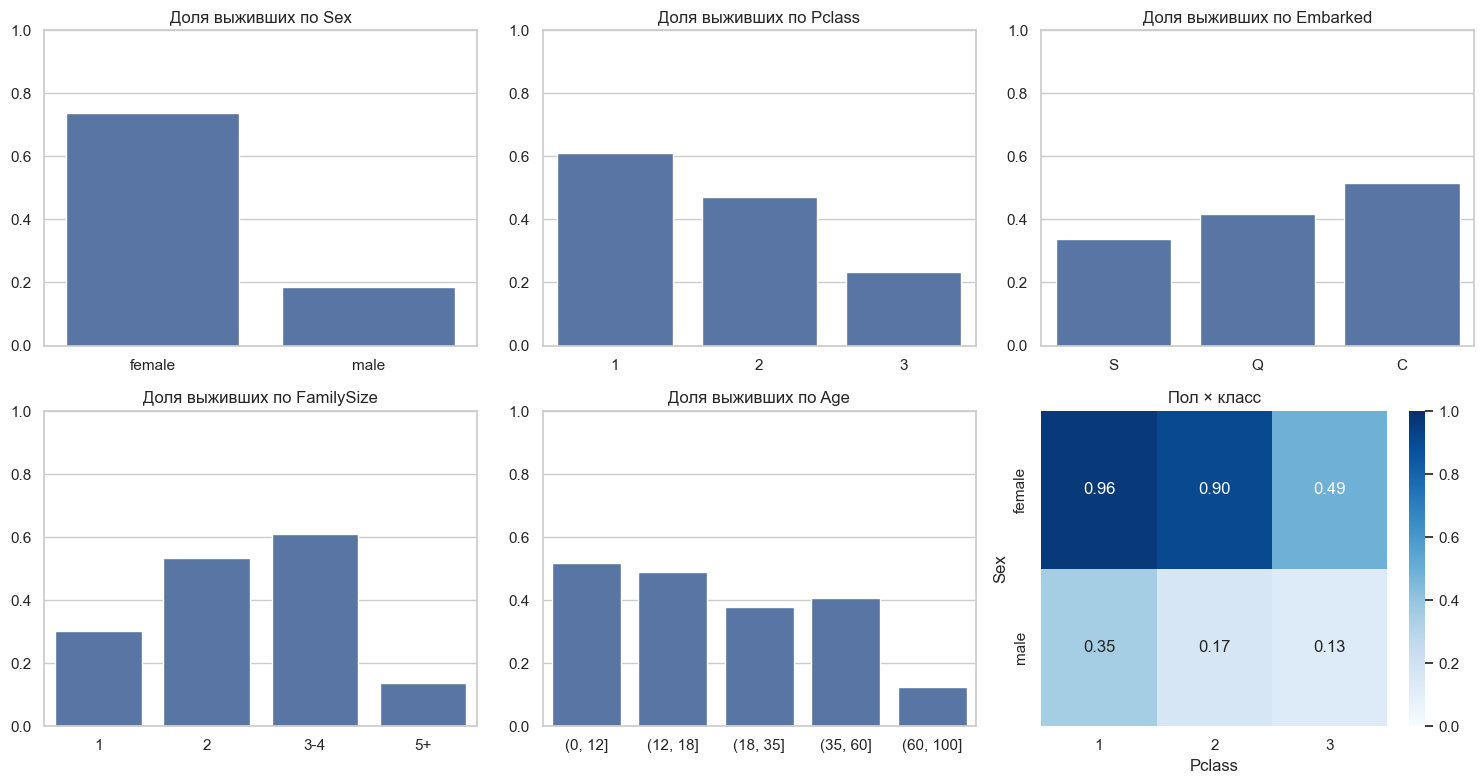

Age пропущен: выжили 27% против 40% у остальных


In [5]:
def add_features(d):
    d = d.copy()
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["Fare_log"] = np.log1p(d["Fare"])
    return d


X_train, X_test = add_features(X_train), add_features(X_test)
tr = X_train.assign(Survived=y_train)
fam = pd.cut(tr.FamilySize, [0, 1, 2, 4, 20], labels=["1", "2", "3-4", "5+"])
agegrp = pd.cut(tr.Age, [0, 12, 18, 35, 60, 100]).astype(str)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, data) in zip(axes.flat, [("Sex", tr.Sex), ("Pclass", tr.Pclass), ("Embarked", tr.Embarked),
                                      ("FamilySize", fam), ("Age", agegrp)]):
    sns.barplot(x=data, y=tr.Survived, errorbar=None, ax=ax, color="#4c72b0",
                order=[str(c) for c in agegrp.sort_values().unique() if c != "nan"] if col == "Age" else None)
    ax.set_title(f"Доля выживших по {col}"); ax.set_ylim(0, 1); ax.set_ylabel(""); ax.set_xlabel("")
sns.heatmap(tr.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean"),
            annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1, 2]); axes[1, 2].set_title("Пол × класс")
plt.tight_layout(); plt.show()

print("Age пропущен: выжили %.0f%% против %.0f%% у остальных" % (100 * tr[tr.Age.isna()].Survived.mean(), 100 * tr[tr.Age.notna()].Survived.mean()))

**Выводы**
- **Пол — главный признак:** выжили 74% женщин и 19% мужчин.
- **Класс:** выжили 61% в 1 классе, 47% во 2 и 23% в 3.
- **Пол и класс вместе:** женщины 1–2 классов почти все выжили (96% и 90%), женщины 3 класса — только половина (49%), мужчины — 35%, 17% и 13%. Именно в «смешанных» группах модель потом и ошибается.
- **Возраст:** дети до 18 лет выживали чаще (около 50% против 40% у взрослых).
- **Семья:** одиночки выживали в 30% случаев, семьи из 2–4 человек — в 53–61%, большие семьи (5+) — в 14%.
- **`Embarked`:** порт C — 52%, S — 34%. Отчасти это потому, что в Cherbourg плыло больше пассажиров 1 класса.
- **Пропуск возраста** тоже несёт информацию: без возраста выжили 27%, с возрастом — 40%.

## 4. Подготовка данных

- **`Id` не используем:** по условию, и он не связан с выживанием.
- **Пропуски `Age`** — заполняем медианой и добавляем столбец «возраст был пропущен» (пропуск сам несёт информацию). **`Embarked`** (2 пропуска) — самым частым значением.
- **Категории `Sex`, `Embarked`** — one-hot (каждая категория отдельным столбцом 0/1). `Pclass` оставляем числом: классы упорядочены.
- **Масштабирование (`StandardScaler`) нужно только SVM и KNN.** Они считают расстояния между пассажирами: без масштаба `Age` (0–80) «перекричит» остальные признаки. Деревьям, лесу и бустингу масштаб не нужен: они просто сравнивают признак с порогом.
- Всё это — внутри `Pipeline`, поэтому медиана, моды и масштаб считаются **только по обучающей части** (в кросс-валидации — только по обучающим фолдам). Утечки из теста нет.

In [6]:
NUM = ["Pclass", "Age", "SibSp", "Parch", "FamilySize", "Fare_log"]
CAT = ["Sex", "Embarked"]


def make_pre(num=NUM, cat=CAT, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), list(num)),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), list(cat)),
    ], remainder="drop")


def make_pipe(clf, scale=False, **kw):
    return Pipeline([("pre", make_pre(scale=scale, **kw)), ("clf", clf)])


print("Признаки после подготовки:", list(make_pre().fit(X_train).get_feature_names_out()))

Признаки после подготовки: ['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__FamilySize', 'num__Fare_log', 'num__missingindicator_Age', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S']


## 5. Baseline и функции оценки

**Baseline** — модель, которая всегда отвечает «погиб» (самый частый класс). Любая настоящая модель должна быть заметно лучше.

**FP и FN в этой задаче.** FP (False Positive) — модель сказала «выжил», а человек погиб. FN (False Negative) — модель сказала «погиб», а человек выжил. FP портит **Precision** (можно ли верить ответу «выжил»), FN портит **Recall** (сколько выживших мы нашли).

,Accuracy,Precision,Recall,F1
Dummy,0.594,0.0,0.0,0.0


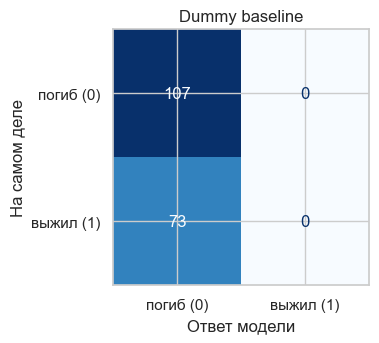

TN=107  FP=0  FN=73  TP=0


In [7]:
def calc_metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}


def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title); ax.set_xlabel("Ответ модели"); ax.set_ylabel("На самом деле")
    plt.tight_layout(); plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")


RES = {}
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
RES["Dummy baseline"] = {"model": dummy, "train": calc_metrics(y_train, dummy.predict(X_train)),
                         "test": calc_metrics(y_test, dummy.predict(X_test)), "pred_test": dummy.predict(X_test), "cv_f1": np.nan}
display(pd.DataFrame(RES["Dummy baseline"]["test"], index=["Dummy"]).round(3))
plot_cm(y_test, RES["Dummy baseline"]["pred_test"], "Dummy baseline")

**Вывод.** Модель «всегда погиб» даёт Accuracy 0.594, но Precision, Recall и F1 равны 0: из 73 выживших она не нашла ни одного. Это ориентир: настоящие модели должны быть заметно лучше нуля по F1.

In [8]:
def run_model(name, clf, grid, scale=False):
    """Подбор параметров кросс-валидацией по F1 на обучающей части, затем метрики на train и test."""
    gs = GridSearchCV(make_pipe(clf, scale=scale), {f"clf__{k}": v for k, v in grid.items()},
                      scoring="f1", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train, groups=g_train)
    best = gs.best_estimator_
    pred_te = best.predict(X_test)
    RES[name] = {"model": best, "scale": scale, "cv_f1": gs.best_score_,
                 "train": calc_metrics(y_train, best.predict(X_train)), "test": calc_metrics(y_test, pred_te), "pred_test": pred_te}
    print(f"{name}: лучшие параметры {({k.replace('clf__', ''): v for k, v in gs.best_params_.items()})}, F1 на кросс-валидации = {gs.best_score_:.3f}")
    display(pd.DataFrame({"train": RES[name]["train"], "test": RES[name]["test"]}).T.round(3))
    plot_cm(y_test, pred_te, name)

## 6. Модели

Параметры каждой модели подбираем кросс-валидацией на обучающей части (метрика F1, одни и те же фолды), тест не трогаем.

### 6.1 Decision Tree
Сначала дерево **без ограничений** — чтобы посмотреть на переобучение (модель «выучила train наизусть»), потом дерево с подобранной глубиной.

In [9]:
dt_full = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train)
print("Дерево без ограничений: глубина", dt_full.named_steps["clf"].get_depth(), ", листьев", dt_full.named_steps["clf"].get_n_leaves())
display(pd.DataFrame({"train": calc_metrics(y_train, dt_full.predict(X_train)),
                      "test": calc_metrics(y_test, dt_full.predict(X_test))}).T.round(3))

Дерево без ограничений: глубина 15 , листьев 161


,Accuracy,Precision,Recall,F1
train,0.986,1.000,0.963,0.981
test,0.800,0.794,0.685,0.735


Decision Tree: лучшие параметры {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 3}, F1 на кросс-валидации = 0.752


,Accuracy,Precision,Recall,F1
train,0.828,0.810,0.714,0.759
test,0.806,0.806,0.685,0.741


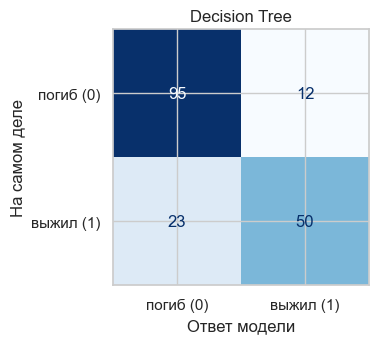

TN=95  FP=12  FN=23  TP=50


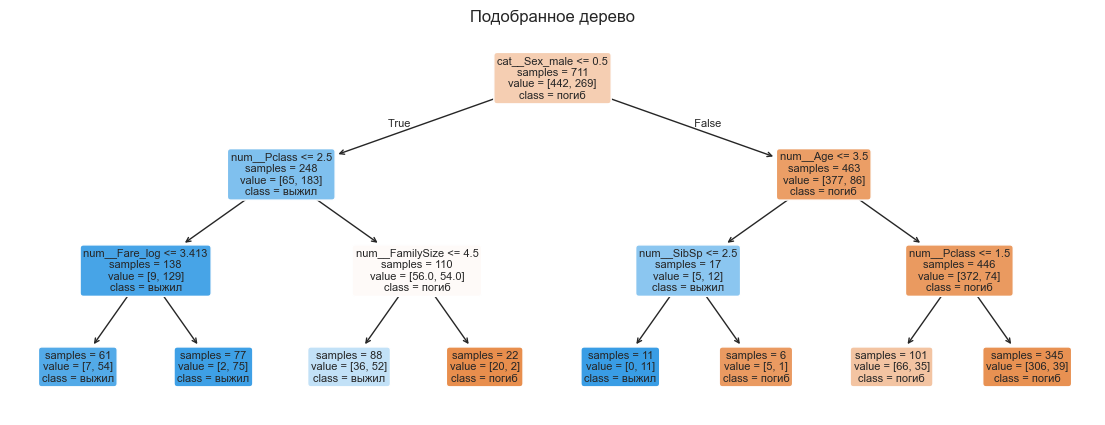

In [10]:
run_model("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
          {"max_depth": [2, 3, 4, 5, 6, 8, 10], "min_samples_leaf": [1, 3, 5, 10, 20], "criterion": ["gini", "entropy"]})

feat_names = list(RES["Decision Tree"]["model"].named_steps["pre"].get_feature_names_out())
plt.figure(figsize=(14, 5))
plot_tree(RES["Decision Tree"]["model"].named_steps["clf"], feature_names=feat_names, class_names=["погиб", "выжил"],
          filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Подобранное дерево"); plt.show()

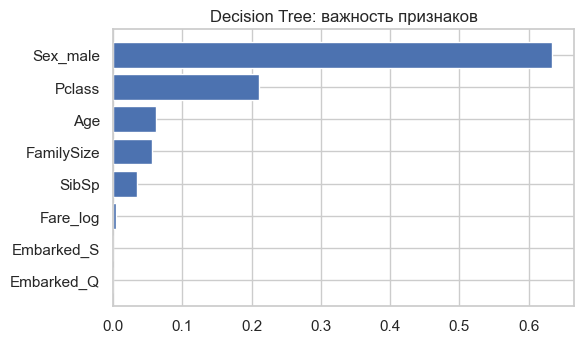

In [11]:
def importance_table(name):
    m = RES[name]["model"]
    return pd.Series(m.named_steps["clf"].feature_importances_, index=m.named_steps["pre"].get_feature_names_out())


def plot_importance(name, top=8):
    imp = importance_table(name).sort_values().tail(top)
    plt.figure(figsize=(6, 3.6))
    plt.barh([i.split("__", 1)[1] for i in imp.index], imp.values, color="#4c72b0")
    plt.title(f"{name}: важность признаков"); plt.tight_layout(); plt.show()


plot_importance("Decision Tree")

**Выводы**
- **Дерево без ограничений** переобучилось: глубина 15, 161 лист, F1 на train 0.98, а на тесте 0.74. Оно «выучило train наизусть».
- **Дерево глубины 3:** F1 на train 0.76, на тесте 0.74. Разрыв маленький, значит переобучения нет.
- **Ошибки:** FP = 12, FN = 23. Дерево чаще пропускает выживших (Recall 0.69), чем ошибается в ответе «выжил» (Precision 0.81).
- **Что выучило дерево, простыми словами:** выжили женщины (кроме больших семей из 3 класса) и маленькие мальчики, остальные погибли.
- **Важность признаков:** `Sex` — 0.63, `Pclass` — 0.21, остальные почти не используются.

### 6.2 Random Forest

Random Forest: лучшие параметры {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 300}, F1 на кросс-валидации = 0.755


,Accuracy,Precision,Recall,F1
train,0.923,0.935,0.855,0.893
test,0.828,0.828,0.726,0.774


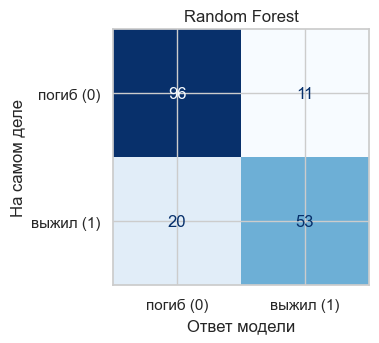

TN=96  FP=11  FN=20  TP=53


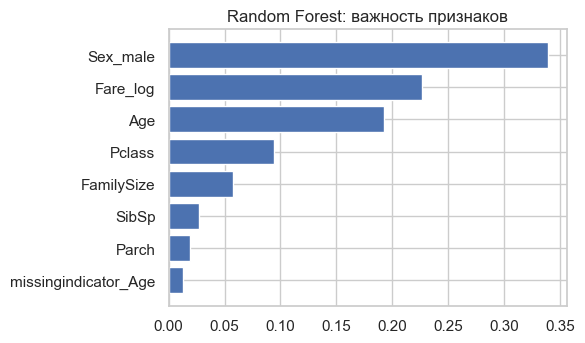

In [12]:
run_model("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
          {"n_estimators": [300], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 2, 4, 8], "max_features": ["sqrt", 0.5]})
plot_importance("Random Forest")

**Выводы**
- **Качество:** F1 на тесте 0.774 (у дерева 0.741), Recall 0.73 (у дерева 0.69). Лес чуть лучше дерева, но разница — около 3 пассажиров.
- **Переобучение:** на train F1 0.89, на тесте 0.77. Деревья в лесу глубокие и подгоняются под train, но усреднение держит качество на новых данных.
- **Важность признаков:** дерево опирается почти только на `Sex` и `Pclass`. Лес использует больше признаков: `Sex` 0.34, `Fare` 0.23, `Age` 0.19, `Pclass` 0.09. Причина: каждое дерево леса видит случайный набор признаков, поэтому в сумме работают все.

### 6.3 Gradient Boosting

Gradient Boosting: лучшие параметры {'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.7}, F1 на кросс-валидации = 0.755


,Accuracy,Precision,Recall,F1
train,0.923,0.946,0.844,0.892
test,0.828,0.828,0.726,0.774


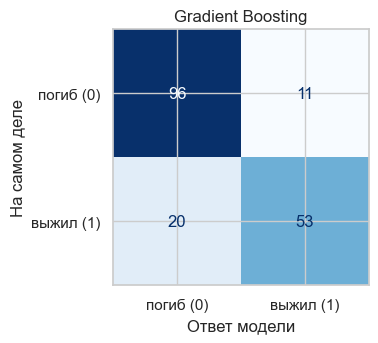

TN=96  FP=11  FN=20  TP=53


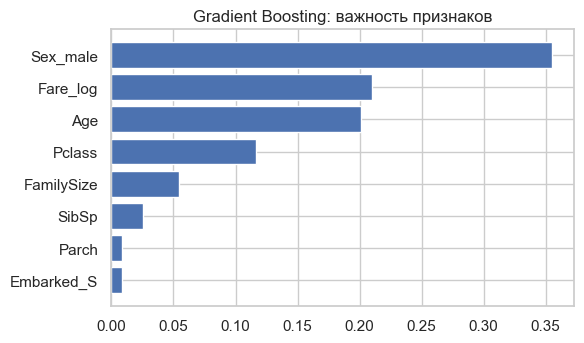

In [13]:
run_model("Gradient Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE),
          {"n_estimators": [100, 200, 300], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4], "subsample": [0.7, 1.0]})
plot_importance("Gradient Boosting")

**Выводы**
- **Качество такое же, как у Random Forest:** F1 на тесте 0.774, модели расходятся только на 4 пассажирах из 180.
- **Идея:** деревья строятся по очереди, каждое исправляет ошибки предыдущих (в лесу деревья независимы).
- **Важность признаков почти та же:** `Sex` 0.36, `Fare` 0.21, `Age` 0.20, `Pclass` 0.12.
- **Переобучение** такое же, как у леса: F1 на train 0.89, на тесте 0.77.

### 6.4 Support Vector Machine
Сначала проверяем, что даёт масштабирование (кросс-валидация на обучающей части, параметры по умолчанию).

,без масштабирования,со StandardScaler
"F1, SVM",0.12,0.745


SVM: лучшие параметры {'C': 10, 'gamma': 0.03, 'kernel': 'rbf'}, F1 на кросс-валидации = 0.757


,Accuracy,Precision,Recall,F1
train,0.835,0.825,0.717,0.767
test,0.800,0.814,0.658,0.727


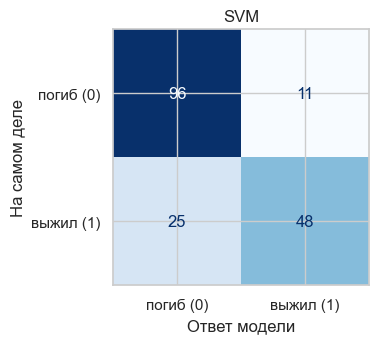

TN=96  FP=11  FN=25  TP=48


In [14]:
def cv_f1(pipe):
    return cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv, scoring="f1", n_jobs=-1).mean()


display(pd.Series({"без масштабирования": cv_f1(make_pipe(SVC(), scale=False)),
                   "со StandardScaler": cv_f1(make_pipe(SVC(), scale=True))}, name="F1, SVM").round(3).to_frame().T)
run_model("SVM", SVC(), {"C": [0.3, 1, 3, 10, 30], "gamma": ["scale", 0.01, 0.03, 0.1, 0.3], "kernel": ["rbf"]}, scale=True)

**Выводы**
- **Масштаб нужен.** Без масштабирования F1 на кросс-валидации 0.12, с масштабом 0.745. SVM строит границу по расстояниям между пассажирами, и без масштаба `Age` (0–80) «перекрикивает» всё остальное, а пол и класс почти не влияют.
- **Качество:** F1 на тесте 0.727, Precision 0.81, Recall 0.66. SVM осторожнее других: реже говорит «выжил», но чаще пропускает выживших. Переобучения нет (F1 train 0.77).

### 6.5 K-Nearest Neighbors

,без масштабирования,со StandardScaler
"F1, KNN",0.638,0.674


KNN: лучшие параметры {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}, F1 на кросс-валидации = 0.715


,Accuracy,Precision,Recall,F1
train,0.986,1.000,0.963,0.981
test,0.800,0.803,0.671,0.731


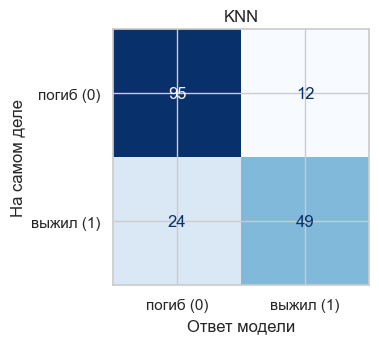

TN=95  FP=12  FN=24  TP=49


In [15]:
display(pd.Series({"без масштабирования": cv_f1(make_pipe(KNeighborsClassifier(), scale=False)),
                   "со StandardScaler": cv_f1(make_pipe(KNeighborsClassifier(), scale=True))}, name="F1, KNN").round(3).to_frame().T)
run_model("KNN", KNeighborsClassifier(),
          {"n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "weights": ["uniform", "distance"], "p": [1, 2]}, scale=True)

**Выводы**
- **Масштаб нужен**, потому что KNN целиком состоит из расстояний между пассажирами. Здесь эффект умеренный: F1 на кросс-валидации 0.638 без масштаба и 0.674 с масштабом.
- **Качество:** F1 на тесте 0.731. По кросс-валидации KNN самый слабый из пяти (0.715).
- **F1 на train = 0.98 — это не переобучение в обычном смысле.** При `weights = distance` каждый пассажир из train сам себе ближайший сосед, поэтому его ответ всегда угадан. Сравнивать нужно тест и кросс-валидацию.

## 7. Честное сравнение моделей

У всех моделей одни и те же данные, одно разбиение, одни фолды и одна процедура подбора параметров. В таблице — метрики на тесте и F1 на кросс-валидации (обучающая часть), по строкам — от лучшей к худшей по F1 на тесте.

,Accuracy,Precision,Recall,F1,F1 > 0.70,F1 на кросс-вал.,F1 на train
Модель,,,,,,,
Random Forest,0.828,0.828,0.726,0.774,да,0.755,0.893
Gradient Boosting,0.828,0.828,0.726,0.774,да,0.755,0.892
Decision Tree,0.806,0.806,0.685,0.741,да,0.752,0.759
KNN,0.800,0.803,0.671,0.731,да,0.715,0.981
SVM,0.800,0.814,0.658,0.727,да,0.757,0.767
Dummy baseline,0.594,0.000,0.000,0.000,нет,NaN,0.000


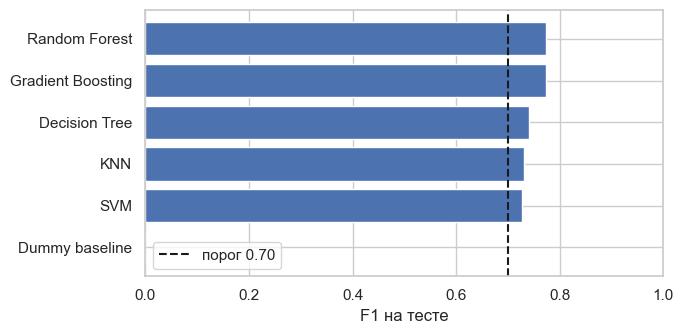

Лучшая модель: Random Forest


In [16]:
order = ["Dummy baseline", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
rows = []
for n in order:
    r = RES[n]
    rows.append({"Модель": n, **{k: r["test"][k] for k in ["Accuracy", "Precision", "Recall", "F1"]},
                 "F1 > 0.70": "да" if r["test"]["F1"] > F1_THRESHOLD else "нет", "F1 на кросс-вал.": r["cv_f1"], "F1 на train": r["train"]["F1"]})
leader = pd.DataFrame(rows).set_index("Модель").sort_values("F1", ascending=False)
display(leader.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
names = leader.index.tolist()[::-1]
ax.barh(names, leader.loc[names, "F1"], color=["#c44e52" if leader.loc[m, "F1"] <= F1_THRESHOLD else "#4c72b0" for m in names])
ax.axvline(F1_THRESHOLD, color="k", ls="--", label="порог 0.70"); ax.set_xlim(0, 1); ax.set_xlabel("F1 на тесте"); ax.legend()
plt.tight_layout(); plt.show()

# лучшая модель: максимум F1 на тесте; при равенстве — выше F1 на кросс-валидации
cand = leader.drop(index="Dummy baseline").assign(F1r=lambda d: d.F1.round(3))
best_name = cand.sort_values(["F1r", "F1 на кросс-вал."], ascending=False).index[0]
print("Лучшая модель:", best_name)

**Выводы**
- **Все пять моделей выше порога 0.70** на тесте: от 0.727 (SVM) до 0.774 (Random Forest и Gradient Boosting). Baseline — 0.
- **Но модели почти не отличаются.** В тесте всего 180 пассажиров, один пассажир меняет Recall на 1.4%. Разница между лучшей и худшей моделью — несколько человек, поэтому нельзя уверенно сказать, что одна модель лучше другой.
- **Лучшая модель — Random Forest.** У неё тот же F1, что и у Gradient Boosting, а при равенстве выбираем по F1 на кросс-валидации (у леса он не ниже).
- **Почему модели получились похожими:** сильных признаков мало (пол, класс, возраст), и простая модель их находит не хуже сложной. SVM и KNN работают только после масштабирования.

## 8. Важность признаков

Для Decision Tree, Random Forest и Gradient Boosting берём `feature_importances_`: насколько признак помогает моделям делить пассажиров на «выжил/погиб» (по train). Столбцы one-hot склеены обратно в исходные признаки.

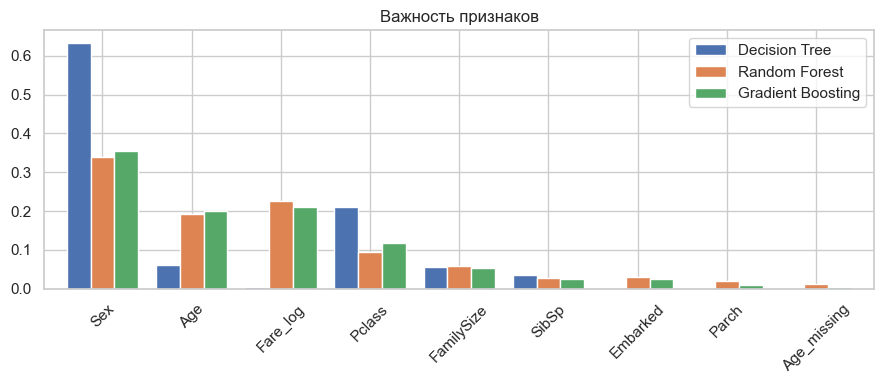

,Sex,Age,Fare_log,Pclass,FamilySize,SibSp,Embarked,Parch,Age_missing
Decision Tree,0.634,0.061,0.003,0.210,0.057,0.035,0.000,0.000,0.000
Random Forest,0.339,0.192,0.226,0.094,0.058,0.027,0.031,0.019,0.013
Gradient Boosting,0.355,0.201,0.210,0.117,0.054,0.025,0.024,0.009,0.005


In [17]:
def orig_name(n):
    n = n.split("__", 1)[1]
    if n.startswith("missingindicator_"):
        return n.replace("missingindicator_", "") + "_missing"
    return n.split("_")[0] if n.split("_")[0] in CAT else n


imp = pd.concat({n: importance_table(n).groupby(orig_name).sum() for n in ["Decision Tree", "Random Forest", "Gradient Boosting"]}, axis=1).fillna(0)
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
imp.plot.bar(figsize=(9, 4), width=0.8); plt.title("Важность признаков"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
display(imp.round(3).T)

**Выводы**
- **Главный признак — пол (`Sex`)** у всех трёх моделей. Дальше идут класс, возраст и плата (порядок зависит от модели). `Embarked`, `SibSp`, `Parch` и пропуск возраста почти не важны.
- **Дерево** опирается почти только на `Sex` и `Pclass`, **лес и бустинг** распределяют важность между `Sex`, `Fare`, `Age`, `Pclass`.
- **С разделом 3 согласуется:** пол, класс, возраст (дети) и размер семьи — то же, что мы видели в данных. `Fare` почти повторяет `Pclass`, поэтому делит с ним важность.
- **Осторожно:** `Age` и `Fare` — непрерывные признаки, и такая важность может немного завышать их роль.

**Можно ли сказать, что важный признак — причина выживания? Нет.** Важность показывает, на что модель опирается при предсказании, а не что вызвало выживание.
- Пол и возраст — это следы правила «женщины и дети первыми в шлюпки»: причина в этом правиле, а не в самом поле.
- Класс — это ещё и место на палубе, ближе или дальше от шлюпок.
- Признаки связаны друг с другом (`Fare` и `Pclass`), поэтому важность между ними делится случайно.
- Данные наблюдательные: поменять человеку пол или класс и посмотреть, что будет, мы не можем.

## 9. Анализ ошибок лучшей модели

Лучшая модель: Random Forest


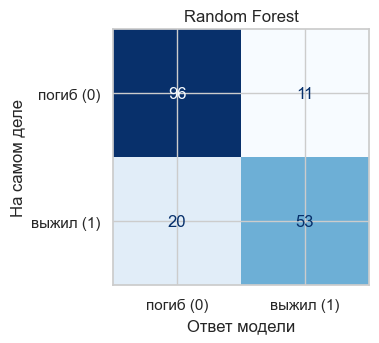

TN=96  FP=11  FN=20  TP=53
Ошибок: 31 из 180 (FP = 11, FN = 20); выживших пропущено 27%, погибших названо выжившими 10%


In [18]:
best = RES[best_name]["model"]
pred = best.predict(X_test)
print("Лучшая модель:", best_name)
plot_cm(y_test, pred, best_name)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Ошибок: {fp + fn} из {len(y_test)} (FP = {fp}, FN = {fn}); "
      f"выживших пропущено {fn / (fn + tp):.0%}, погибших названо выжившими {fp / (fp + tn):.0%}")

In [19]:
def score(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


te = X_test.assign(y=y_test, pred=pred, score=score(best, X_test))
te["err"] = (te.y != te.pred).astype(int)
te["FN"] = ((te.y == 1) & (te.pred == 0)).astype(int)
te["FP"] = ((te.y == 0) & (te.pred == 1)).astype(int)
te["AgeGroup"] = np.where(te.Age.isna(), "нет данных", pd.cut(te.Age, [0, 18, 35, 60, 100]).astype(str))


def group_err(cols):
    g = te.groupby(cols).agg(n=("y", "size"), выжили=("y", "sum"), ошибок=("err", "sum"), FP=("FP", "sum"), FN=("FN", "sum"))
    g["доля ошибок"] = (g["ошибок"] / g["n"]).round(2)
    return g


display(group_err(["Sex", "Pclass"]))
display(group_err("AgeGroup"))

n  выжили  ошибок  FP  FN  доля ошибок
Sex    Pclass                                         
female 1       19      19       0   0   0         0.00
       2       13      13       0   0   0         0.00
       3       34      18      10   6   4         0.29
male   1       20       9      10   5   5         0.50
       2       18       2       2   0   2         0.11
       3       76      12       9   0   9         0.12

,n,выжили,ошибок,FP,FN,доля ошибок
AgeGroup,,,,,,
"(0, 18]",26,13,2,2,0,0.08
"(18, 35]",71,28,15,4,11,0.21
"(35, 60]",35,13,6,2,4,0.17
"(60, 100]",6,3,1,0,1,0.17
нет данных,42,16,7,3,4,0.17


In [20]:
cols = ["Id", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Embarked", "y", "pred", "score"]
print("Самые уверенные FP (модель сказала «выжил», а он погиб):")
display(te[te.FP == 1].sort_values("score", ascending=False)[cols].head(3).round(2))
print("Самые уверенные FN (модель сказала «погиб», а он выжил):")
display(te[te.FN == 1].sort_values("score")[cols].head(3).round(2))

Самые уверенные FP (модель сказала «выжил», а он погиб):


,Id,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,y,pred,score
771,10000147,female,18.0,3,6.75,0,0,Q,0,1,0.82
318,76699932,male,30.0,1,27.75,0,0,C,0,1,0.67
725,10000101,male,37.0,1,53.10,1,0,S,0,1,0.65


Самые уверенные FN (модель сказала «погиб», а он выжил):


,Id,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,y,pred,score
162,41913454,male,19.0,2,10.50,0,0,S,1,0,0.01
686,10000062,male,80.0,1,30.00,0,0,S,1,0,0.04
208,26438145,male,NaN,3,23.25,2,0,Q,1,0,0.06


### Не держится ли качество на признаках, которые «узнают» конкретного пассажира?
Берём параметры лучшей модели и меняем набор признаков: добавляем запрещённый `Id`, по очереди убираем `Age` и `Fare` (почти уникальные числа). Если бы качество держалось на «запоминании», `Id` его бы заметно поднял.

In [21]:
best_clf = best.named_steps["clf"]
best_scale = RES[best_name]["scale"]
variants = {"Основной набор": dict(), "+ Id": dict(num=NUM + ["Id"]),
            "без Age": dict(num=[c for c in NUM if c != "Age"]), "без Fare_log": dict(num=[c for c in NUM if c != "Fare_log"])}
rows = []
for label, kw in variants.items():
    p = make_pipe(clone(best_clf), scale=best_scale, **kw)
    cvs = cross_val_score(p, X_train, y_train, groups=g_train, cv=cv, scoring="f1", n_jobs=-1)
    p.fit(X_train, y_train)
    rows.append({"Набор признаков": label, "F1 кросс-вал.": cvs.mean(), "F1 train": f1_score(y_train, p.predict(X_train)),
                 "F1 test": f1_score(y_test, p.predict(X_test))})
display(pd.DataFrame(rows).set_index("Набор признаков").round(3))

,F1 кросс-вал.,F1 train,F1 test
Набор признаков,,,
Основной набор,0.755,0.893,0.774
+ Id,0.732,0.909,0.777
без Age,0.712,0.840,0.763
без Fare_log,0.737,0.863,0.773


**Выводы**
- **Ошибок 31 из 180:** FP = 11, FN = 20. Выживших пропущено 27%, а погибших названо выжившими 10%. Модель осторожная: чаще говорит «погиб».
- **Где нет ошибок:** женщины 1–2 классов (32 человека, все выжили).
- **Где ошибок много** — группы, где шансы около 50/50:
  - мужчины 1 класса: 10 ошибок из 20 (выжила примерно половина);
  - женщины 3 класса: 10 из 34 (тоже примерно половина);
  - мужчины 3 класса: 9 из 76, выжили 12 человек, а модель сказала «погиб» всем.
  В таких группах признаки не показывают, кто из пассажиров выживет.
- **По возрасту:** дети до 18 лет — 2 ошибки из 26, возраст 18–35 — 15 из 71.
- **Примеры.** FP: Id 10000147 (женщина 18 лет, 3 класс), Id 10000101 и 76699932 (мужчины 1 класса): подходят под «выживший», но погибли. FN: Id 41913454 (мужчина 19 лет, 2 класс), Id 10000062 (мужчина 80 лет, 1 класс), Id 26438145 (мужчина 3 класса): подходят под «погиб», но выжили. Почему именно они, по признакам не объяснить: у нас нет данных про каюту и шлюпку.
- **Держится ли качество на идентификаторах? Нет.** С `Id` качество не растёт: на кросс-валидации 0.755 → 0.732, на тесте 0.774 → 0.777, а на train растёт (0.89 → 0.91): модель просто начинает запоминать. Без `Age` и без `Fare` качество падает (0.712 и 0.737), то есть они реально помогают, но это не «узнавание» людей. Разницы в 1–2% — в пределах шума.

## 10. Посылка для `test.csv`

Берём лучшую модель из раздела 7 с найденными параметрами, **переобучаем на всём `train.csv`** (891 пассажир), предсказываем метки для `test.csv` и сохраняем `submission.csv` в формате `sample_submission.csv`.

In [22]:
final_pipe = clone(RES[best_name]["model"])
Xf_all = add_features(X)

cvs = cross_val_score(final_pipe, Xf_all, y, groups=groups_all, cv=cv, scoring="f1", n_jobs=-1)
print(f"{best_name}: F1 на кросс-валидации по всему train.csv = {cvs.mean():.3f} ± {cvs.std():.3f}")

final_pipe.fit(Xf_all, y)
pred_sub = final_pipe.predict(add_features(sub)[Xf_all.columns]).astype(int)
pd.DataFrame({"Id": sub["Id"].values, "Survived": pred_sub}).to_csv("submission.csv", index=False)

chk = pd.read_csv("submission.csv")
assert list(chk.columns) == list(sample.columns) and len(chk) == len(sample) and (chk.Id.values == sample.Id.values).all()
assert set(chk.Survived.unique()) <= {0, 1}
print("submission.csv: %d строк, формат как в sample_submission; предсказано «выжил»: %.1f%% (в train — %.1f%%)"
      % (len(chk), 100 * chk.Survived.mean(), 100 * y.mean()))

Random Forest: F1 на кросс-валидации по всему train.csv = 0.753 ± 0.023


submission.csv: 1000 строк, формат как в sample_submission; предсказано «выжил»: 34.0% (в train — 38.4%)


## 11. Итоги

**Итоги**
- Сделано: baseline (F1 = 0), пять моделей, сравнение, важность признаков, анализ ошибок, посылка `submission.csv`.
- **Порог F1 > 0.70 пройден:** все пять моделей дали 0.727–0.774 на тесте и 0.715–0.757 на кросс-валидации. Лучшая — Random Forest (0.774).
- **Что определяет выживание в данных:** пол, класс и возраст. Больше из этих признаков выжать трудно.
- **Для `test.csv`** Random Forest обучен на всём `train.csv`, ожидаемый F1 около 0.75 (кросс-валидация: 0.753 ± 0.023).

**Ограничения**
- Реальный F1 на `test.csv` знает только организатор: у нас есть оценка, а не гарантия.
- Тест маленький (180 пассажиров), поэтому различия между моделями — в пределах шума.
- Важность признаков показывает связь, а не причину.